# TPOD ile Finansal Dolandırıcılık Tespiti
## Çoklu Veri Seti Üzerinde Karşılaştırmalı Analiz

**Algoritma:** TPOD — Two-Parameter Outlier Detection  
**Makale:** Zhang & Yang, *Axioms 2023, 12, 425*

**Test Edilen Veri Setleri:**

| # | Veri Seti | Alan | Kaynak | Dosya |
|---|---|---|---|---|
| 1 | ULB Credit Card Fraud | Kredi kartı işlemleri | Kaggle (ULB) | `creditcard.csv` |
| 2 | PaySim | Mobil para transferi | Kaggle | `PS_20174392719_1491204439457_log.csv` |
| 3 | Bank Account Fraud (BAF) | Banka hesabı açılışı | Kaggle (NeurIPS 2022) | `Base.csv` |
| 4 | Sparkov Credit Card Transactions | Kredi kartı işlemleri (sentetik) | Kaggle / Hugging Face | `fraudTrain.csv` |

**İndirme Linkleri:**
- ULB: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- PaySim: https://www.kaggle.com/datasets/ealaxi/paysim1
- BAF: https://www.kaggle.com/datasets/sgpjesus/bank-account-fraud-dataset-neurips-2022
- Bank Transaction: https://www.kaggle.com/datasets/valakhorasani/bank-transaction-dataset-for-fraud-detection

**Not:** Tüm dosyalar bu notebook ile aynı klasörde olmalı.


## 1. Kütüphane Kurulumu

In [1]:
%pip install numpy pandas scikit-learn matplotlib -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings, os
from itertools import product
warnings.filterwarnings("ignore")

from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.neighbors import KDTree
from sklearn.decomposition import PCA
from sklearn.metrics import (roc_auc_score, f1_score,
                             precision_score, recall_score, roc_curve)

print("Tum kutuphaneler yuklendi")

Tum kutuphaneler yuklendi


## 2. TPOD Algoritması

In [3]:
def natural_neighbors(X):
    """Algorithm 1: Natural Neighbor Search"""
    n = len(X)
    tree = KDTree(X)
    k = 1
    prev_zero_count = -1

    while True:
        _, knn_idx = tree.query(X, k=k + 1)
        knn_idx = knn_idx[:, 1:]
        nb = np.zeros(n, dtype=int)
        for i in range(n):
            for j in knn_idx[i]:
                nb[j] += 1
        zero_count = int(np.sum(nb == 0))
        if zero_count == 0 or zero_count == prev_zero_count:
            break
        prev_zero_count = zero_count
        k += 1

    return k, knn_idx


def run_tpod(X, c=0.9, eta=0.01, eps=1e-5):
    """Algorithm 2: TPOD Score Computation"""
    n = len(X)

    # 1. Dogal komşuluk
    lambda_, nan_idx = natural_neighbors(X)

    # 2. Adaptif kernel genisligi (Formul 10)
    d_lambda = np.zeros(n)
    for i in range(n):
        dists = np.linalg.norm(X[nan_idx[i]] - X[i], axis=1)
        d_lambda[i] = np.mean(dists)
    d_max, d_min = np.max(d_lambda), np.min(d_lambda)
    h = c * (d_max + d_min + eps - d_lambda)
    h = np.maximum(h, eps)

    # 3. Yerel yogunluk (Formul 11)
    rho = np.zeros(n)
    for i in range(n):
        sq = np.sum((X - X[i]) ** 2, axis=1)
        sq[i] = np.inf
        rho[i] = np.mean(np.exp(-sq / (h[i] ** 2 + eps)))

    # 4. Goreli mesafe (Formul 12-14)
    RD = np.zeros(n)
    for i in range(n):
        neighbors = X[nan_idx[i]]
        lam = len(nan_idx[i])
        d_bar = np.mean(np.linalg.norm(neighbors - X[i], axis=1))
        if lam < 2:
            D_bar = d_bar + eps
        else:
            inner = [np.linalg.norm(neighbors[a] - neighbors[b])
                     for a in range(lam) for b in range(a+1, lam)]
            D_bar = np.mean(inner) if inner else d_bar + eps
        RD[i] = d_bar / (D_bar + eps)

    # 5. TPOD skoru + esik (Formul 15-16)
    scores = RD / (rho + eps)
    sigma  = eta * np.mean(scores)
    labels = (scores > sigma).astype(int)

    return scores, labels, lambda_


def normalize_scores(scores):
    s_min, s_max = scores.min(), scores.max()
    if s_max > s_min:
        return (scores - s_min) / (s_max - s_min)
    return scores


def compute_metrics(y, scores, labels):
    return {
        "AUC":       roc_auc_score(y, normalize_scores(scores)),
        "F1":        f1_score(y, labels, zero_division=0),
        "Precision": precision_score(y, labels, zero_division=0),
        "Recall":    recall_score(y, labels, zero_division=0),
    }


def grid_search_tpod(X, y,
                     eta_range=[0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.5, 1.0],
                     c_range=[0.5, 0.6, 0.7, 0.8, 0.9, 1.0]):
    """F1 skorunu maksimize eden optimal eta ve c parametrelerini bulur."""
    best  = {"eta": None, "c": None, "f1": -1, "auc": -1}
    rows  = []
    total = len(eta_range) * len(c_range)
    print("  " + str(total) + " kombinasyon deneniyor...")

    for i, (eta, c) in enumerate(product(eta_range, c_range)):
        scores, labels, _ = run_tpod(X, c=c, eta=eta)
        f1  = f1_score(y, labels, zero_division=0)
        auc = roc_auc_score(y, normalize_scores(scores))
        rows.append({"eta": eta, "c": c, "F1": f1, "AUC": auc})
        if f1 > best["f1"]:
            best = {"eta": eta, "c": c, "f1": f1, "auc": auc}
        if (i+1) % 10 == 0:
            print("  " + str(i+1) + "/" + str(total) + " tamamlandi...")

    return best, pd.DataFrame(rows).sort_values("F1", ascending=False)


print("TPOD algoritmasi hazir")

TPOD algoritmasi hazir


## 3. Veri Setleri — Yükleme ve Ön İşleme

Her veri seti için:
- Sayısal özellikler seçilir
- Kategorik özellikler label encoding ile sayısala dönüştürülür
- MinMaxScaler ile [0,1] normalizasyonu yapılır
- Örnekleme: TPOD hesaplama maliyeti nedeniyle her veri setinden 1500 örnek alınır


In [4]:
SAMPLE_SIZE = 1500   # Her veri setinden alinacak ornek sayisi
scaler = MinMaxScaler()
datasets = {}

# ── Dosya yolu cozumleyici: alt klasorlerde de arar ──────────────────────
import glob
DATA_ROOT = ".."  # veri setleri ust klasorde
def find_file(name, patterns=()):
    """Dosyayi once dogrudan, sonra DATA_ROOT altinda recursive arar."""
    if os.path.exists(name):
        return name
    for pat in (name,) + tuple(patterns):
        hits = glob.glob(os.path.join(DATA_ROOT, "**", pat), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(name + " bulunamadi!")

# ── 1. ULB Credit Card Fraud ─────────────────────────────────────────────
def load_creditcard(path="creditcard.csv"):
    print("  ULB Credit Card Fraud yukleniyor...", end=" ")
    path = find_file(path, ())
    df = pd.read_csv(path)
    fraud  = df[df["Class"] == 1]
    normal = df[df["Class"] == 0].sample(
        n=min(SAMPLE_SIZE - len(fraud), len(df[df["Class"]==0])),
        random_state=42)
    df = pd.concat([fraud, normal]).sample(frac=1, random_state=42)
    X  = df.drop(columns=["Class","Time"]).values.astype(float)
    y  = df["Class"].values.astype(int)
    print("OK  shape=" + str(X.shape) +
          "  fraud=" + str(y.sum()) + " (" + f"{y.mean()*100:.1f}%)")
    return X, y

# ── 2. PaySim ────────────────────────────────────────────────────────────
def load_paysim(path="PS_20174392719_1491204439457_log.csv"):
    print("  PaySim yukleniyor...", end=" ")
    path = find_file(path, ("PS_*log*.csv", "*paysim*.csv"))
    df = pd.read_csv(path)
    # Sadece TRANSFER ve CASH_OUT tiplerinde fraud var
    df = df[df["type"].isin(["TRANSFER","CASH_OUT"])].copy()
    # Kategorik sutunu encode et
    le = LabelEncoder()
    df["type_enc"] = le.fit_transform(df["type"])
    feat_cols = ["type_enc","amount","oldbalanceOrg","newbalanceOrig",
                 "oldbalanceDest","newbalanceDest"]
    fraud  = df[df["isFraud"] == 1].sample(
        n=min(500, len(df[df["isFraud"]==1])), random_state=42)
    normal = df[df["isFraud"] == 0].sample(
        n=min(SAMPLE_SIZE - len(fraud), len(df[df["isFraud"]==0])),
        random_state=42)
    df = pd.concat([fraud, normal]).sample(frac=1, random_state=42)
    X  = df[feat_cols].values.astype(float)
    y  = df["isFraud"].values.astype(int)
    print("OK  shape=" + str(X.shape) +
          "  fraud=" + str(y.sum()) + " (" + f"{y.mean()*100:.1f}%)")
    return X, y

# ── 3. Bank Account Fraud (BAF) ──────────────────────────────────────────
def load_baf(path="Base.csv"):
    print("  Bank Account Fraud (BAF) yukleniyor...", end=" ")
    path = find_file(path, ())
    df = pd.read_csv(path)
    # Kategorik sutunlari encode et
    # Not: one-hot denendi (3 seed, c=0.5/0.7/0.9): AUC ~0.40; label encoding ~0.46.
    # One-hot boyutu 31->~53'e cikarip mesafeleri seyreltiyor; label encoding korundu.
    cat_cols = df.select_dtypes(include=["object","category"]).columns.tolist()
    le = LabelEncoder()
    for col in cat_cols:
        df[col] = le.fit_transform(df[col].astype(str))
    fraud  = df[df["fraud_bool"] == 1].sample(
        n=min(500, len(df[df["fraud_bool"]==1])), random_state=42)
    normal = df[df["fraud_bool"] == 0].sample(
        n=min(SAMPLE_SIZE - len(fraud), len(df[df["fraud_bool"]==0])),
        random_state=42)
    df = pd.concat([fraud, normal]).sample(frac=1, random_state=42)
    feat_cols = [c for c in df.columns if c != "fraud_bool"]
    X  = df[feat_cols].values.astype(float)
    y  = df["fraud_bool"].values.astype(int)
    print("OK  shape=" + str(X.shape) +
          "  fraud=" + str(y.sum()) + " (" + f"{y.mean()*100:.1f}%)")
    return X, y

# ── 4. Sparkov Credit Card Transactions ─────────────────────────────────
def load_sparkov(path="fraudTrain.csv"):
    print("  Sparkov Credit Card Transactions yukleniyor...", end=" ")
    path = find_file(path, ("fraudTrain*.csv",))
    df = pd.read_csv(path)
    # Turetilmis ozellikler: islem saati, musteri yasi, musteri-isyeri mesafesi
    t = pd.to_datetime(df["trans_date_trans_time"])
    df["hour"] = t.dt.hour
    df["age"]  = (t - pd.to_datetime(df["dob"])).dt.days / 365.25
    df["dist"] = np.sqrt((df["lat"] - df["merch_lat"])**2 +
                         (df["long"] - df["merch_long"])**2)
    df["category_enc"] = LabelEncoder().fit_transform(df["category"].astype(str))
    df["gender_enc"]   = (df["gender"] == "M").astype(int)
    # Kimlik/kisisel bilgi sutunlari (isim, kart no, trans_num vb.) kullanilmaz
    feat_cols = ["amt","category_enc","gender_enc","city_pop",
                 "hour","age","dist","lat","long"]
    fraud  = df[df["is_fraud"] == 1].sample(
        n=min(500, len(df[df["is_fraud"]==1])), random_state=42)
    normal = df[df["is_fraud"] == 0].sample(
        n=min(SAMPLE_SIZE - len(fraud), len(df[df["is_fraud"]==0])),
        random_state=42)
    df = pd.concat([fraud, normal]).sample(frac=1, random_state=42)
    X  = df[feat_cols].values.astype(float)
    y  = df["is_fraud"].values.astype(int)
    print("OK  shape=" + str(X.shape) +
          "  fraud=" + str(y.sum()) + " (" + f"{y.mean()*100:.1f}%)")
    return X, y


# ── Veri setlerini yukle ──────────────────────────────────────────────────
print("Veri setleri yukleniyor...")
print()

DATASET_INFO = {
    "ULB_CreditCard": {
        "loader": load_creditcard,
        "color":  "#0A7EA4",
        "label":  "ULB Credit Card\n(Kredi Karti)",
        "desc":   "Avrupa kredi karti islemleri (Eylul 2013)"
    },
    "PaySim": {
        "loader": load_paysim,
        "color":  "#15803D",
        "label":  "PaySim\n(Mobil Para Transferi)",
        "desc":   "Afrika mobil odeme sistemi simulasyonu"
    },
    "BAF": {
        "loader": load_baf,
        "color":  "#D97706",
        "label":  "Bank Account Fraud\n(Banka Hesabi)",
        "desc":   "Banka hesabi acilis basvurulari (NeurIPS 2022)"
    },
    "Sparkov": {
        "loader": load_sparkov,
        "color":  "#7C3AED",
        "label":  "Sparkov\n(Kart Islemleri)",
        "desc":   "Sentetik kredi karti islemleri (ABD, 2019-2020)"
    },
}

datasets = {}
failed   = []

for ds_name, info in DATASET_INFO.items():
    try:
        X_raw, y   = info["loader"]()
        X_scaled   = scaler.fit_transform(X_raw)
        datasets[ds_name] = {**info, "X": X_scaled, "y": y}
    except FileNotFoundError as e:
        print("  ATLA: " + str(e))
        failed.append(ds_name)
    except Exception as e:
        print("  HATA (" + ds_name + "): " + str(e))
        failed.append(ds_name)

print()
print("Yuklenen veri seti sayisi: " + str(len(datasets)))
if failed:
    print("Atlanalar: " + ", ".join(failed))

Veri setleri yukleniyor...

  ULB Credit Card Fraud yukleniyor... 

OK  shape=(1500, 29)  fraud=492 (32.8%)
  PaySim yukleniyor... 

OK  shape=(1500, 6)  fraud=500 (33.3%)
  Bank Account Fraud (BAF) yukleniyor... 

OK  shape=(1500, 31)  fraud=500 (33.3%)
  Sparkov Credit Card Transactions yukleniyor... 

OK  shape=(1500, 9)  fraud=500 (33.3%)

Yuklenen veri seti sayisi: 4


## 4. Grid Search — Optimal η ve c Parametrelerinin Belirlenmesi

Her veri seti için F1 skorunu maksimize eden η ve c kombinasyonu aranır.


In [5]:
print("=" * 55)
print("GRID SEARCH - OPTIMAL PARAMETRE BELIRLEME")
print("=" * 55)

optimal_params = {}

for ds_name, ds in datasets.items():
    print()
    print(ds_name + " — " + ds["desc"])
    print("-" * 45)
    best, df_grid = grid_search_tpod(ds["X"], ds["y"])
    optimal_params[ds_name] = best

    print("  En iyi eta : " + str(best["eta"]))
    print("  En iyi c   : " + str(best["c"]))
    print("  F1         : " + f"{best['f1']:.4f}")
    print("  AUC        : " + f"{best['auc']:.4f}")
    print()
    print("  Top 5 kombinasyon:")
    print(df_grid.head().to_string(index=False))

print()
print("=" * 55)
print("OZET — OPTIMAL PARAMETRELER")
print("=" * 55)
for ds_name, p in optimal_params.items():
    print(ds_name.ljust(20) +
          " eta=" + str(p["eta"]) +
          "  c=" + str(p["c"]) +
          "  F1=" + f"{p['f1']:.4f}")

GRID SEARCH - OPTIMAL PARAMETRE BELIRLEME

ULB_CreditCard — Avrupa kredi karti islemleri (Eylul 2013)
---------------------------------------------
  48 kombinasyon deneniyor...


  10/48 tamamlandi...


  20/48 tamamlandi...


  30/48 tamamlandi...


  40/48 tamamlandi...


...

  10/48 tamamlandi...


  20/48 tamamlandi...


  30/48 tamamlandi...


  40/48 tamamlandi...


  En iyi eta : 0.01
  En iyi c   : 1.0
  F1         : 0.5657
  AUC        : 0.7198

  Top 5 kombinasyon:
 eta   c       F1      AUC
0.01 1.0 0.565742 0.719794
0.01 0.9 0.547309 0.720224
0.01 0.8 0.522340 0.718394
0.05 0.5 0.512069 0.679780
0.01 0.7 0.505338 0.712992

OZET — OPTIMAL PARAMETRELER
ULB_CreditCard       eta=0.01  c=0.5  F1=0.7726
PaySim               eta=0.005  c=0.6  F1=0.5193
BAF                  eta=0.005  c=0.9  F1=0.5003
Sparkov              eta=0.01  c=1.0  F1=0.5657


## 5. TPOD — Optimal Parametrelerle Çalıştır

In [6]:
all_results = {}
all_metrics = {}

for ds_name, ds in datasets.items():
    X, y = ds["X"], ds["y"]
    p    = optimal_params[ds_name]

    print(ds_name + " (eta=" + str(p["eta"]) + ", c=" + str(p["c"]) + ")")
    scores, labels, lam = run_tpod(X, c=p["c"], eta=p["eta"])
    m = compute_metrics(y, scores, labels)

    all_results[ds_name] = {"scores": scores, "labels": labels, "lambda": lam}
    all_metrics[ds_name] = m

    print("  lambda=" + str(lam) +
          "  AUC=" + f"{m['AUC']:.4f}" +
          "  F1=" + f"{m['F1']:.4f}" +
          "  Recall=" + f"{m['Recall']:.4f}")
    print()

print("Tum veri setleri tamamlandi")

ULB_CreditCard (eta=0.01, c=0.5)


  lambda=19  AUC=0.9079  F1=0.7726  Recall=0.7215

PaySim (eta=0.005, c=0.6)


  lambda=15  AUC=0.7034  F1=0.5193  Recall=0.5120

BAF (eta=0.005, c=0.9)


  lambda=16  AUC=0.4606  F1=0.5003  Recall=1.0000

Sparkov (eta=0.01, c=1.0)


  lambda=14  AUC=0.7198  F1=0.5657  Recall=0.9380

Tum veri setleri tamamlandi


## 6. Görselleştirme — Her Veri Seti İçin

Kaydedildi: tpod_fraud_ulb_creditcard.png


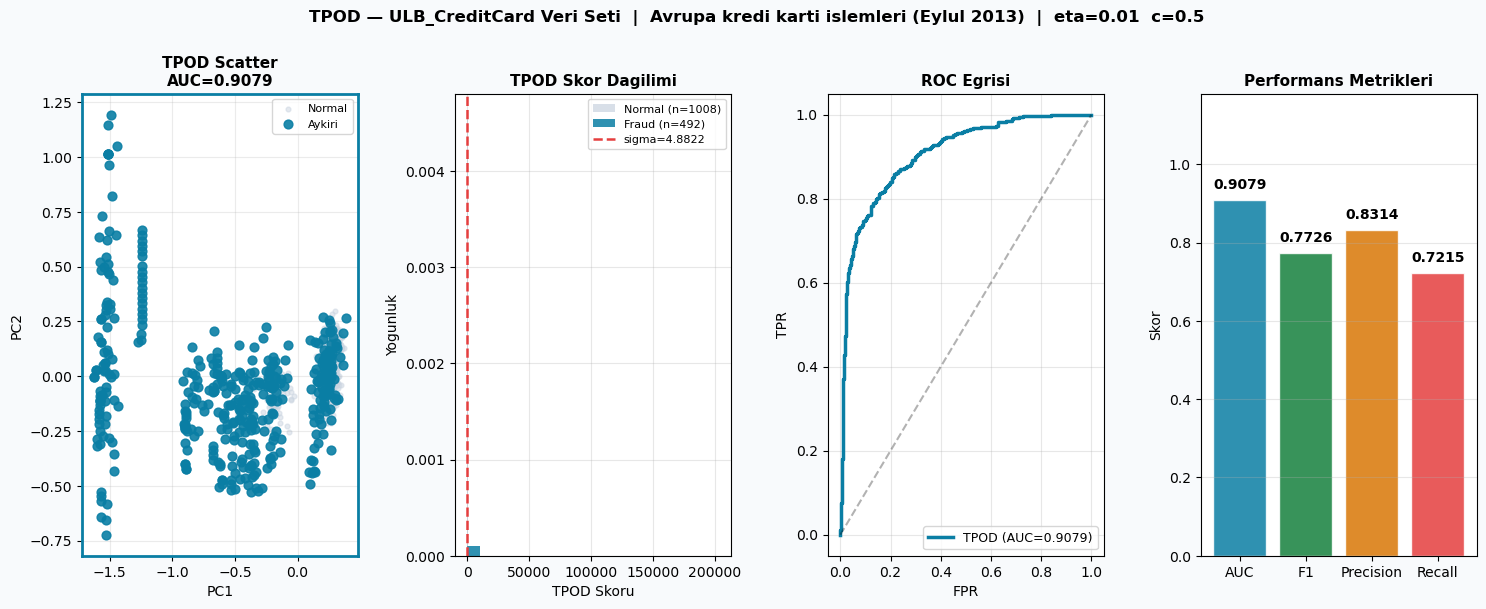

Kaydedildi: tpod_fraud_paysim.png


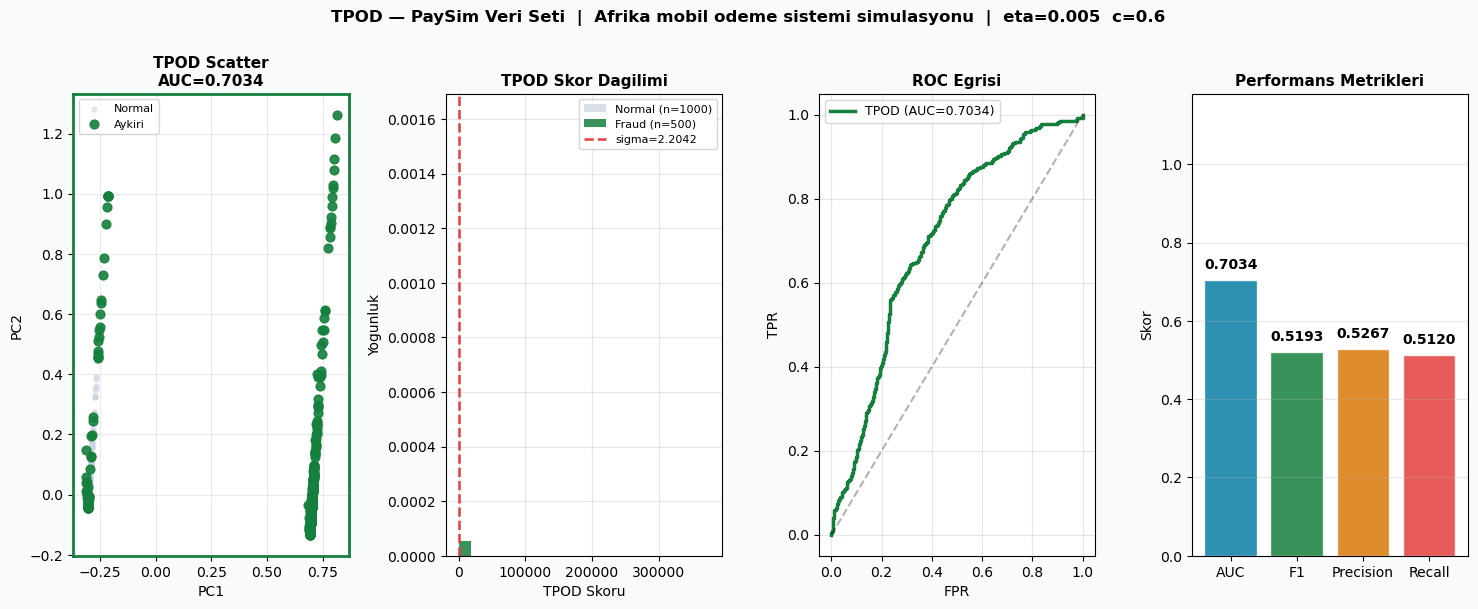

Kaydedildi: tpod_fraud_baf.png


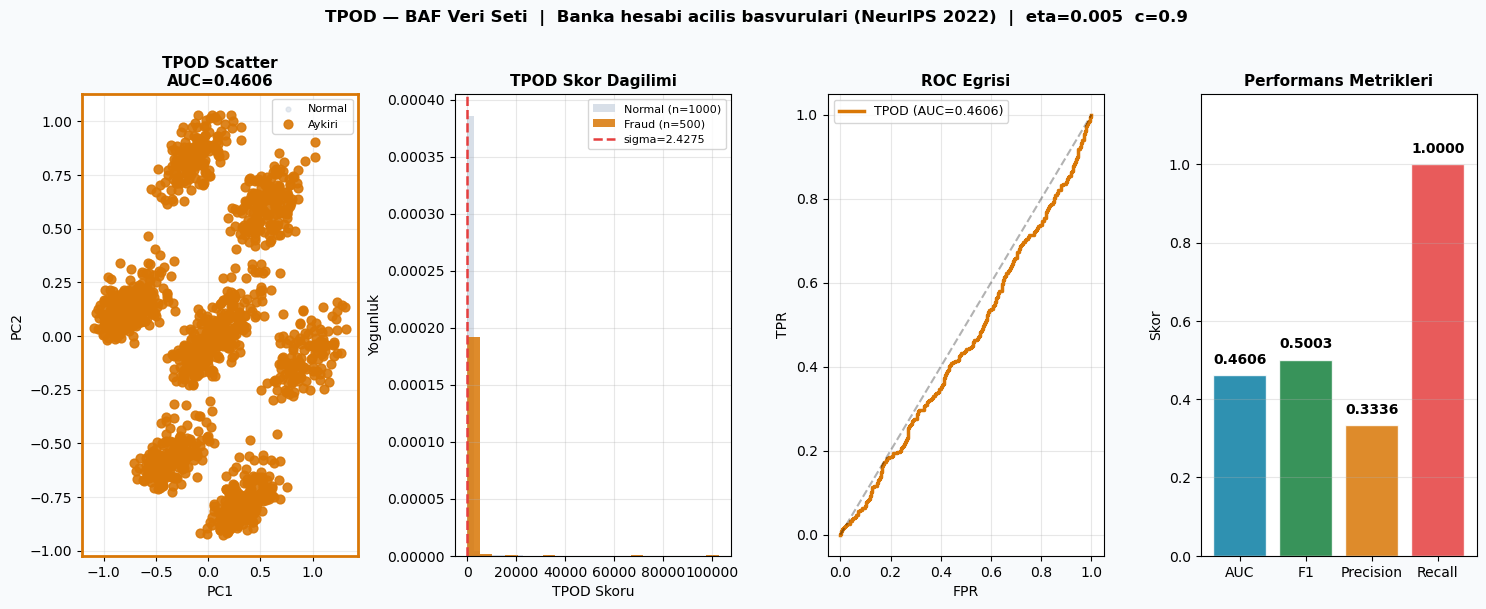

Kaydedildi: tpod_fraud_sparkov.png


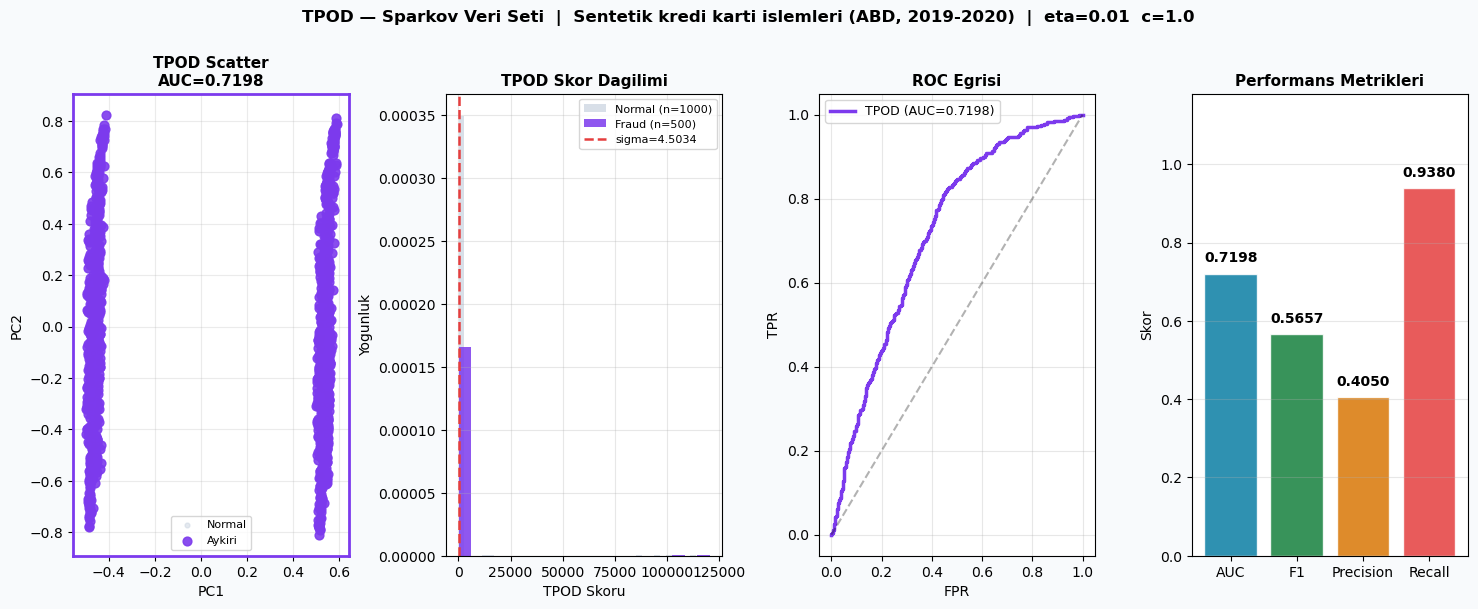

In [7]:
def plot_dataset(ds_name, ds, result, metrics, opt_p):
    X, y  = ds["X"], ds["y"]
    color = ds["color"]
    scores = result["scores"]
    labels = result["labels"]

    pca  = PCA(n_components=2, random_state=42)
    X_2d = pca.fit_transform(X)

    fig = plt.figure(figsize=(18, 6))
    fig.patch.set_facecolor("#F8FAFC")
    gs  = gridspec.GridSpec(1, 4, figure=fig, wspace=0.35)

    # Scatter plot
    ax0 = fig.add_subplot(gs[0])
    ax0.scatter(X_2d[labels==0,0], X_2d[labels==0,1],
                c="#CBD5E1", s=12, alpha=0.5, label="Normal")
    ax0.scatter(X_2d[labels==1,0], X_2d[labels==1,1],
                c=color, s=40, alpha=0.9, label="Aykiri", zorder=5)
    t = "TPOD Scatter\nAUC=" + f"{metrics['AUC']:.4f}"
    ax0.set_title(t, fontweight="bold", fontsize=11)
    ax0.set_xlabel("PC1"); ax0.set_ylabel("PC2")
    ax0.legend(fontsize=8)
    ax0.set_facecolor("white")
    ax0.grid(True, alpha=0.25)
    for spine in ax0.spines.values():
        spine.set_edgecolor(color); spine.set_linewidth(2)

    # TPOD skor dagilimi
    ax1 = fig.add_subplot(gs[1])
    sigma = opt_p["eta"] * np.mean(scores)
    ax1.hist(scores[y==0], bins=40, color="#CBD5E1", alpha=0.75,
             label="Normal (n=" + str((y==0).sum()) + ")", density=True)
    ax1.hist(scores[y==1], bins=20, color=color, alpha=0.85,
             label="Fraud (n=" + str((y==1).sum()) + ")", density=True)
    ax1.axvline(x=sigma, color="#E53E3E", linestyle="--",
                linewidth=1.8, label="sigma=" + f"{sigma:.4f}")
    ax1.set_title("TPOD Skor Dagilimi", fontweight="bold", fontsize=11)
    ax1.set_xlabel("TPOD Skoru"); ax1.set_ylabel("Yogunluk")
    ax1.legend(fontsize=8)
    ax1.set_facecolor("white"); ax1.grid(alpha=0.3)

    # ROC egri
    ax2 = fig.add_subplot(gs[2])
    fpr, tpr, _ = roc_curve(y, normalize_scores(scores))
    ax2.plot(fpr, tpr, color=color, linewidth=2.5,
             label="TPOD (AUC=" + f"{metrics['AUC']:.4f})")
    ax2.plot([0,1],[0,1],"k--", alpha=0.3)
    ax2.set_title("ROC Egrisi", fontweight="bold", fontsize=11)
    ax2.set_xlabel("FPR"); ax2.set_ylabel("TPR")
    ax2.legend(fontsize=9)
    ax2.set_facecolor("white"); ax2.grid(alpha=0.3)

    # Metrik bar chart
    ax3 = fig.add_subplot(gs[3])
    mnames = ["AUC","F1","Precision","Recall"]
    mvals  = [metrics[m] for m in mnames]
    mcols  = ["#0A7EA4","#15803D","#D97706","#E53E3E"]
    bars   = ax3.bar(mnames, mvals, color=mcols, alpha=0.85, edgecolor="white")
    ax3.set_ylim(0, 1.18)
    ax3.set_title("Performans Metrikleri", fontweight="bold", fontsize=11)
    ax3.set_ylabel("Skor")
    ax3.set_facecolor("white"); ax3.grid(axis="y", alpha=0.3)
    for bar, val in zip(bars, mvals):
        ax3.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.03,
                 f"{val:.4f}", ha="center", fontsize=10, fontweight="bold")

    param_str = "eta=" + str(opt_p["eta"]) + "  c=" + str(opt_p["c"])
    sup = "TPOD — " + ds_name + " Veri Seti  |  " + ds["desc"] + "  |  " + param_str
    fig.suptitle(sup, fontsize=12, fontweight="bold", y=1.02)

    fname = "tpod_fraud_" + ds_name.lower().replace("-","_") + ".png"
    plt.savefig(fname, dpi=150, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    print("Kaydedildi: " + fname)
    plt.show()
    plt.close()


for ds_name, ds in datasets.items():
    plot_dataset(ds_name, ds, all_results[ds_name],
                 all_metrics[ds_name], optimal_params[ds_name])

## 7. Tüm Veri Setleri Karşılaştırması

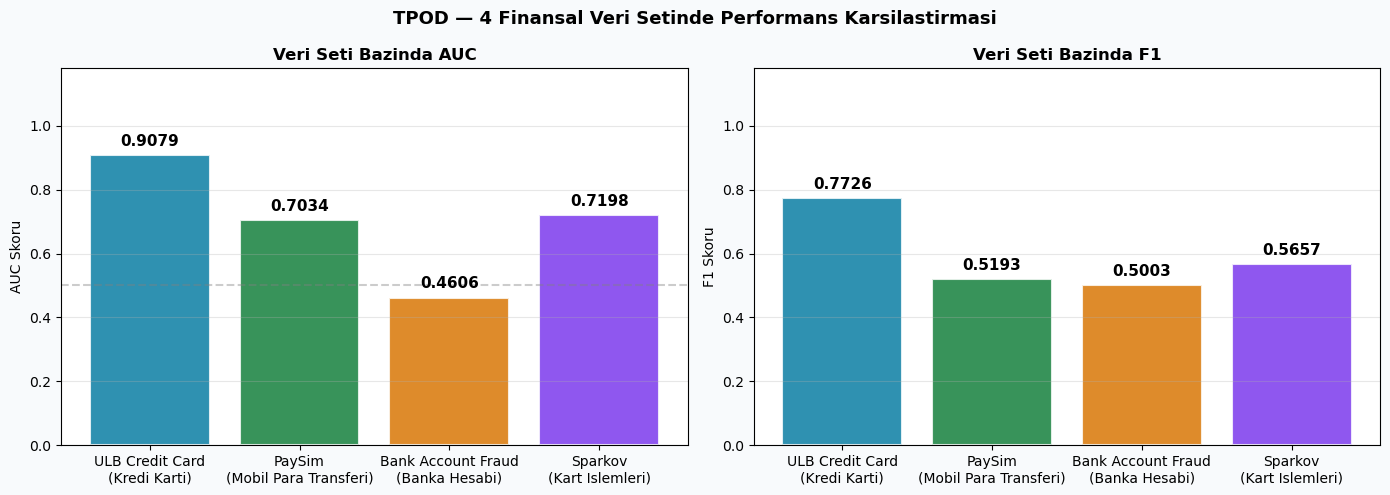

Kaydedildi: tpod_fraud_karsilastirma.png


In [8]:
# Bar chart karsilastirma
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor("#F8FAFC")

ds_names = list(datasets.keys())
x        = np.arange(len(ds_names))
ds_cols  = [datasets[d]["color"] for d in ds_names]

for ax, mname in zip(axes, ["AUC","F1"]):
    vals = [all_metrics[ds][mname] for ds in ds_names]
    bars = ax.bar(x, vals, color=ds_cols, alpha=0.85, edgecolor="white", linewidth=1.5)
    ax.set_ylim(0, 1.18)
    ax.set_xticks(x)
    ax.set_xticklabels([datasets[d]["label"] for d in ds_names], fontsize=10)
    ax.set_title("Veri Seti Bazinda " + mname, fontweight="bold", fontsize=12)
    ax.set_ylabel(mname + " Skoru")
    ax.set_facecolor("white")
    ax.grid(axis="y", alpha=0.3)
    if mname == "AUC":
        ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.4)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.03,
                f"{val:.4f}", ha="center", fontsize=11, fontweight="bold")

plt.suptitle("TPOD — 4 Finansal Veri Setinde Performans Karsilastirmasi",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("tpod_fraud_karsilastirma.png", dpi=150, bbox_inches="tight")
plt.show()
print("Kaydedildi: tpod_fraud_karsilastirma.png")

## 8. ROC Eğrileri — 4 Veri Seti Birlikte

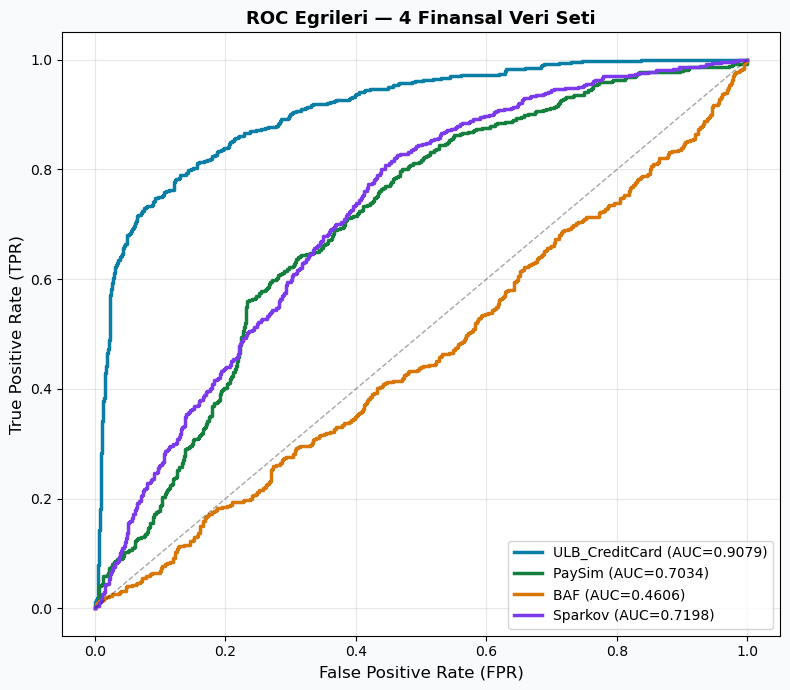

Kaydedildi: tpod_fraud_roc.png


In [9]:
fig, ax = plt.subplots(figsize=(8, 7))
fig.patch.set_facecolor("#F8FAFC")
ax.set_facecolor("white")

for ds_name, ds in datasets.items():
    scores = all_results[ds_name]["scores"]
    y      = ds["y"]
    fpr, tpr, _ = roc_curve(y, normalize_scores(scores))
    auc = all_metrics[ds_name]["AUC"]
    ax.plot(fpr, tpr, color=ds["color"], linewidth=2.5,
            label=ds_name + " (AUC=" + f"{auc:.4f})")

ax.plot([0,1],[0,1],"k--", alpha=0.35, linewidth=1)
ax.set_xlabel("False Positive Rate (FPR)", fontsize=12)
ax.set_ylabel("True Positive Rate (TPR)", fontsize=12)
ax.set_title("ROC Egrileri — 4 Finansal Veri Seti",
             fontweight="bold", fontsize=13)
ax.legend(fontsize=10, loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("tpod_fraud_roc.png", dpi=150, bbox_inches="tight")
plt.show()
print("Kaydedildi: tpod_fraud_roc.png")

## 9. Özet Tablo

In [10]:
print("=" * 75)
print("TPOD — 4 FINANSAL VERI SETINDE PERFORMANS OZETI")
print("=" * 75)
print()
print("%-22s %-6s %-6s  %8s %8s %10s %8s" % (
    "Veri Seti","eta","c","AUC","F1","Precision","Recall"))
print("-" * 75)

for ds_name, ds in datasets.items():
    p = optimal_params[ds_name]
    m = all_metrics[ds_name]
    print("%-22s %-6s %-6s  %8.4f %8.4f %10.4f %8.4f" % (
        ds_name, str(p["eta"]), str(p["c"]),
        m["AUC"], m["F1"], m["Precision"], m["Recall"]))

print("=" * 75)
print()

# En iyi ve en kotu AUC
best_ds  = max(all_metrics, key=lambda d: all_metrics[d]["AUC"])
worst_ds = min(all_metrics, key=lambda d: all_metrics[d]["AUC"])
print("En yuksek AUC : " + best_ds  + " (" + f"{all_metrics[best_ds]['AUC']:.4f})")
print("En dusuk AUC  : " + worst_ds + " (" + f"{all_metrics[worst_ds]['AUC']:.4f})")
print()
avg_auc = np.mean([all_metrics[d]["AUC"] for d in all_metrics])
avg_f1  = np.mean([all_metrics[d]["F1"]  for d in all_metrics])
print("Ortalama AUC  : " + f"{avg_auc:.4f}")
print("Ortalama F1   : " + f"{avg_f1:.4f}")

TPOD — 4 FINANSAL VERI SETINDE PERFORMANS OZETI

Veri Seti              eta    c            AUC       F1  Precision   Recall
---------------------------------------------------------------------------
ULB_CreditCard         0.01   0.5       0.9079   0.7726     0.8314   0.7215
PaySim                 0.005  0.6       0.7034   0.5193     0.5267   0.5120
BAF                    0.005  0.9       0.4606   0.5003     0.3336   1.0000
Sparkov                0.01   1.0       0.7198   0.5657     0.4050   0.9380

En yuksek AUC : ULB_CreditCard (0.9079)
En dusuk AUC  : BAF (0.4606)

Ortalama AUC  : 0.6979
Ortalama F1   : 0.5895


## 10. Bildiri Özeti

Bildiri özeti notebook dışına taşındı: `TPOD_Bildiri_Ozet.docx` (aynı klasörde).
